# Training

### Benchmarking trees v1

In [ ]:
from training import TreeModelBenchmarker
import pandas as pd
import numpy as np

In [ ]:
X_train_df = pd.read_csv('./data/final/X_train.csv')
X_test_df = pd.read_csv('./data/final/X_test.csv')
y_train_df = pd.read_csv('./data/final/y_train.csv').reset_index()
y_test_df = pd.read_csv('./data/final/y_test.csv').reset_index()

In [ ]:
print(len(X_train_df))
print(len(y_train_df))
print(len(X_test_df))
print(len(y_test_df))

2636
2636
659
659


In [ ]:
y_test_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 659 entries, 0 to 658
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   index   659 non-null    int64
 1   target  659 non-null    int64
dtypes: int64(2)
memory usage: 10.4 KB


In [ ]:
X_train_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2636 entries, 0 to 2635
Data columns (total 17 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   SEQN                2636 non-null   float64
 1   is_female           2636 non-null   float64
 2   diff_hearing        2636 non-null   float64
 3   diff_seeing         2636 non-null   float64
 4   diff_concentrating  2636 non-null   float64
 5   diff_walking        2636 non-null   float64
 6   diff_remembering    2636 non-null   float64
 7   confusion           2636 non-null   float64
 8   norm_age            2636 non-null   float64
 9   education           2636 non-null   float64
 10  has_diabetes        2636 non-null   int64  
 11  has_hchol           2636 non-null   int64  
 12  has_osteo           2636 non-null   int64  
 13  has_hbp             2636 non-null   int64  
 14  condition           2636 non-null   int64  
 15  marital             2636 non-null   float64
 16  RXDCOUNT         

In [ ]:
# Turn to matrix

X_train = (X_train_df.drop(columns=['SEQN'])).to_numpy()
X_test = (X_test_df.drop(columns=['SEQN'])).to_numpy()
y_train = (y_train_df.drop(columns=['index'])).to_numpy().ravel()
y_test = (y_test_df.drop(columns=['index'])).to_numpy().ravel()

In [ ]:
X_train.shape

(2636, 16)

In [ ]:
y_train.shape

(2636,)

In [ ]:
tmb = TreeModelBenchmarker(
    X_train=X_train,
    X_test=X_test,
    y_train=y_train,
    y_test=y_test
)

In [ ]:
tmb.execute_pipeline()

Iniciando otimização para: RandomForest...
Fitting 5 folds for each of 108 candidates, totalling 540 fits


RandomForest concluído em 47.28s. ROC-AUC: 0.7470

Iniciando otimização para: XGBoost...
Fitting 5 folds for each of 288 candidates, totalling 1440 fits
XGBoost concluído em 27.83s. ROC-AUC: 0.7313

Iniciando otimização para: LightGBM...
Fitting 5 folds for each of 96 candidates, totalling 480 fits


./venv/lib64/python3.14/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
./venv/lib64/python3.14/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
./venv/lib64/python3.14/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
./venv/lib64/python3.14/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
./venv/lib64/python3.14/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
./venv/lib64/python3.14/site-packages/sklearn/utils/validati

LightGBM concluído em 234.51s. ROC-AUC: 0.7501



./venv/lib64/python3.14/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
./venv/lib64/python3.14/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


In [13]:
metrics_df = tmb.get_metrics_report()

In [15]:
metrics_df

,Best_Params,ROC_AUC,F1_Score,Precision,Recall,Brier_Score,True_Positives,False_Positives,True_Negatives,False_Negatives,Training_Time_sec
LightGBM,"{'learning_rate': 0.1, 'max_depth': -1, 'min_c...",0.750087,0.559036,0.753247,0.444444,0.229315,116,38,360,145,234.51
RandomForest,"{'max_depth': None, 'max_features': 'sqrt', 'm...",0.746958,0.536458,0.837398,0.394636,0.201036,103,20,378,158,47.28
XGBoost,"{'colsample_bytree': 1.0, 'learning_rate': 0.1...",0.731315,0.541063,0.732026,0.429119,0.220762,112,41,357,149,27.83


In [18]:
metrics_df.to_csv('./results/benchmark_v1_tree.csv')

### v2 - testing LightGBM on a wider HP search
LightGBM foi o melhor no geral, vamos adaptar a função de custo e rodar de novo

In [1]:
from training import TreeModelBenchmarker
import pandas as pd
import numpy as np

In [2]:
X_train_df = pd.read_csv('./data/final/X_train.csv')
X_test_df = pd.read_csv('./data/final/X_test.csv')
y_train_df = pd.read_csv('./data/final/y_train.csv').reset_index()
y_test_df = pd.read_csv('./data/final/y_test.csv').reset_index()

In [3]:
print(len(X_train_df))
print(len(y_train_df))
print(len(X_test_df))
print(len(y_test_df))

2636
2636
659
659


In [4]:
y_test_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 659 entries, 0 to 658
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   index   659 non-null    int64
 1   target  659 non-null    int64
dtypes: int64(2)
memory usage: 10.4 KB


In [5]:
X_train_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2636 entries, 0 to 2635
Data columns (total 17 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   SEQN                2636 non-null   float64
 1   is_female           2636 non-null   float64
 2   diff_hearing        2636 non-null   float64
 3   diff_seeing         2636 non-null   float64
 4   diff_concentrating  2636 non-null   float64
 5   diff_walking        2636 non-null   float64
 6   diff_remembering    2636 non-null   float64
 7   confusion           2636 non-null   float64
 8   norm_age            2636 non-null   float64
 9   education           2636 non-null   float64
 10  has_diabetes        2636 non-null   int64  
 11  has_hchol           2636 non-null   int64  
 12  has_osteo           2636 non-null   int64  
 13  has_hbp             2636 non-null   int64  
 14  condition           2636 non-null   int64  
 15  marital             2636 non-null   float64
 16  RXDCOUNT         

In [6]:
# Turn to matrix

X_train = (X_train_df.drop(columns=['SEQN'])).to_numpy()
X_test = (X_test_df.drop(columns=['SEQN'])).to_numpy()
y_train = (y_train_df.drop(columns=['index'])).to_numpy().ravel()
y_test = (y_test_df.drop(columns=['index'])).to_numpy().ravel()

In [7]:
X_train.shape

(2636, 16)

In [8]:
y_train.shape

(2636,)

In [9]:
tmb = TreeModelBenchmarker(
    X_train=X_train,
    X_test=X_test,
    y_train=y_train,
    y_test=y_test
)

In [ ]:
tmb.execute_pipeline() # 648 candidates, 3240 fits - exactlty the same results

In [ ]:
metrics_df = tmb.get_metrics_report()

### v3 - SHAP based feature pruning 

In [ ]:
metrics_df

In [10]:
import pandas as pd
import shap
import lightgbm as lgb
from sklearn.model_selection import GridSearchCV

model_v1 = lgb.LGBMClassifier(random_state=42, class_weight='balanced', verbose=-1)

param_grid = {
    'n_estimators': [300],
    'max_depth': [-1],
    'learning_rate': [0.1],
    'num_leaves': [63],
    'min_child_samples': [20],
    'subsample': [0.8]
}

grid = GridSearchCV(model_v1, param_grid, cv=5, scoring='roc_auc', n_jobs=-1)
grid.fit(X_train, y_train)

best_model = grid.best_estimator_

explainer = shap.TreeExplainer(best_model)
shap_values = explainer.shap_values(X_test)

./venv/lib64/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
./venv/lib64/python3.14/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
./venv/lib64/python3.14/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
./venv/lib64/python3.14/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
./venv/lib64/python3.14/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
./ven

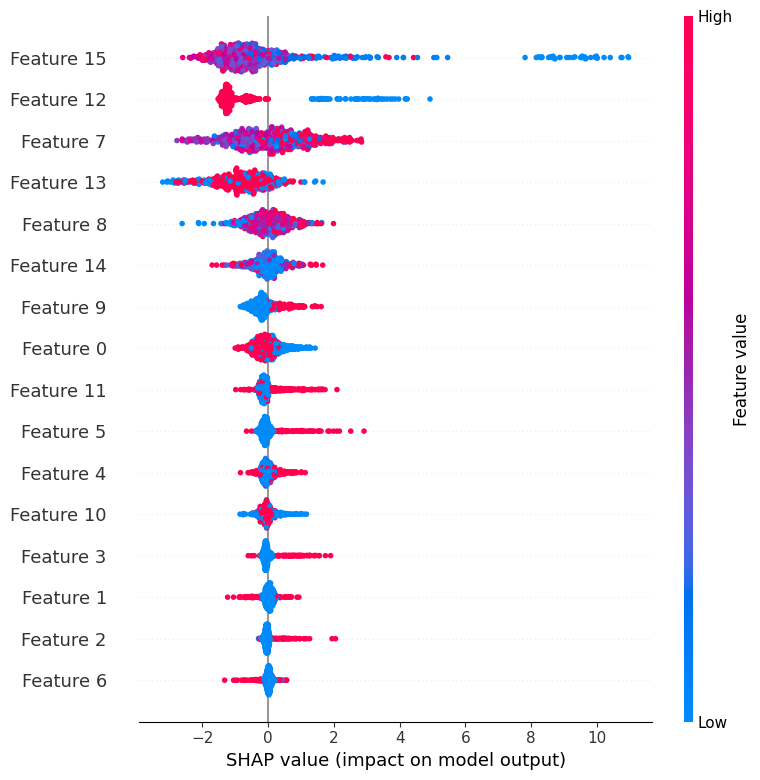

In [11]:
shap.summary_plot(shap_values, X_test)

In [12]:
shap_values.shape

(659, 16)

In [13]:
X_train_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2636 entries, 0 to 2635
Data columns (total 17 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   SEQN                2636 non-null   float64
 1   is_female           2636 non-null   float64
 2   diff_hearing        2636 non-null   float64
 3   diff_seeing         2636 non-null   float64
 4   diff_concentrating  2636 non-null   float64
 5   diff_walking        2636 non-null   float64
 6   diff_remembering    2636 non-null   float64
 7   confusion           2636 non-null   float64
 8   norm_age            2636 non-null   float64
 9   education           2636 non-null   float64
 10  has_diabetes        2636 non-null   int64  
 11  has_hchol           2636 non-null   int64  
 12  has_osteo           2636 non-null   int64  
 13  has_hbp             2636 non-null   int64  
 14  condition           2636 non-null   int64  
 15  marital             2636 non-null   float64
 16  RXDCOUNT         

In [14]:
import numpy as np
import pandas as pd

feats = list(X_train_df.drop(columns=['SEQN']).columns)
shap_df = pd.DataFrame()

for i in range(shap_values.shape[1]):
    shap_df[feats[i]] = (pd.Series(shap_values[:,i]))

    shap_df[feats[i]] = shap_df[feats[i]].abs()

    shap_df[feats[i]] = shap_df[feats[i]].mean()

importance = {feat_name : [shap_df[feat_name].iloc[0]] for feat_name in feats}

df = pd.DataFrame(importance)

df

,is_female,diff_hearing,diff_seeing,diff_concentrating,diff_walking,diff_remembering,confusion,norm_age,education,has_diabetes,has_hchol,has_osteo,has_hbp,condition,marital,RXDCOUNT
0,0.283528,0.121253,0.097702,0.156079,0.168946,0.190252,0.087645,0.864708,0.447827,0.3082,0.168647,0.2417,1.247828,0.860278,0.316384,1.462027


In [15]:
# bad way to see it, let's transpose that

new_df = pd.DataFrame({'feature_name':[], 'shap_stat':[]})

for f in df.columns:
    new_df.loc[len(new_df)] = [f, df[f].iloc[0]]

new_df

,feature_name,shap_stat
0,is_female,0.283528
1,diff_hearing,0.121253
2,diff_seeing,0.097702
3,diff_concentrating,0.156079
4,diff_walking,0.168946
5,diff_remembering,0.190252
6,confusion,0.087645
7,norm_age,0.864708
8,education,0.447827
9,has_diabetes,0.308200


In [16]:
new_df.sort_values('shap_stat',ascending=True)

,feature_name,shap_stat
6,confusion,0.087645
2,diff_seeing,0.097702
1,diff_hearing,0.121253
3,diff_concentrating,0.156079
10,has_hchol,0.168647
4,diff_walking,0.168946
5,diff_remembering,0.190252
11,has_osteo,0.241700
0,is_female,0.283528
9,has_diabetes,0.308200


Let's try slicing on 0.1, 0.2, 0.3, 0.4, 0.5 and rerunning the tests 

In [17]:
shap_values[:,1].shape

(659,)

In [21]:
import warnings
# Silence the scikit-learn warning triggered by LightGBM's default internal names
warnings.filterwarnings("ignore", category=UserWarning, module="sklearn.utils.validation")


In [22]:
thresholds = [0.1, 0.2, 0.3, 0.4 ,0.5]

feature_importances_df = new_df.copy()

X_train_df = pd.read_csv('./data/final/X_train.csv').drop(columns=['SEQN'])
X_test_df = pd.read_csv('./data/final/X_test.csv').drop(columns=['SEQN'])
y_train_df = pd.read_csv('./data/final/y_train.csv').reset_index(drop=True)
y_test_df = pd.read_csv('./data/final/y_test.csv').reset_index(drop=True)


for t in thresholds:

    # Get the features that pass the thresholds
    selected_features = feature_importances_df[feature_importances_df['shap_stat'] >= t]['feature_name']

    # Get new dataframes with only the selected features  
    X_train_df = X_train_df[selected_features]
    X_test_df = X_test_df[selected_features]

    # For Debugging
    print(f'\n === RUNNING FOR T = {t} ===\n')
    print(f'TRAIN_X: N° of samples {len(X_train_df)}; N° of features: {len(X_train_df.columns)}')
    print(f'TRAIN_Y: N° of samples {len(y_train_df)}; N° of features: {len(y_train_df.columns)}')
    print(f'TEST_X: N° of samples {len(X_test_df)}; N° of features: {len(X_test_df.columns)}')
    print(f'TEST_Y: N° of samples {len(y_test_df)}; N° of features: {len(y_test_df.columns)}')


    # Turn to matrix
    X_train = X_train_df.to_numpy()
    X_test = X_test_df.to_numpy()
    y_train = y_train_df.to_numpy().ravel()
    y_test = y_test_df.to_numpy().ravel()

    # Instantiate a new TreeModelBenchmarker
    tmb = TreeModelBenchmarker(
        X_train=X_train,
        X_test=X_test,
        y_train=y_train,
        y_test=y_test
        )
    

    # Run the pipeline 
    tmb.execute_pipeline()

    # Get the metrics 
    metrics_df = tmb.get_metrics_report()

    # Save the metrics 
    metrics_df.to_csv(f'./results/benchmark_v2_t_{t:.2f}.csv')


 === RUNNING FOR T = 0.1 ===

TRAIN_X: N° of samples 2636; N° of features: 14
TRAIN_Y: N° of samples 2636; N° of features: 1
TEST_X: N° of samples 659; N° of features: 14
TEST_Y: N° of samples 659; N° of features: 1
Iniciando otimização para: LightGBM...
Fitting 5 folds for each of 24 candidates, totalling 120 fits
LightGBM concluído em 74.69s. ROC-AUC: 0.7490


 === RUNNING FOR T = 0.2 ===

TRAIN_X: N° of samples 2636; N° of features: 9
TRAIN_Y: N° of samples 2636; N° of features: 1
TEST_X: N° of samples 659; N° of features: 9
TEST_Y: N° of samples 659; N° of features: 1
Iniciando otimização para: LightGBM...
Fitting 5 folds for each of 24 candidates, totalling 120 fits
LightGBM concluído em 47.44s. ROC-AUC: 0.7198


 === RUNNING FOR T = 0.3 ===

TRAIN_X: N° of samples 2636; N° of features: 7
TRAIN_Y: N° of samples 2636; N° of features: 1
TEST_X: N° of samples 659; N° of features: 7
TEST_Y: N° of samples 659; N° of features: 1
Iniciando otimização para: LightGBM...
Fitting 5 folds fo

In [29]:
all_metrics_df = pd.DataFrame({col:[] for col in metrics_df.columns}).drop(columns='Unnamed: 0')


In [30]:
all_metrics_df['threshold'] = 0
all_metrics_df

,Best_Params,ROC_AUC,F1_Score,Precision,Recall,Brier_Score,True_Positives,False_Positives,True_Negatives,False_Negatives,Training_Time_sec,threshold


In [36]:

for t in thresholds:
    metrics_df = pd.read_csv(f'./results/benchmark_v2_t_{t:.2f}.csv').drop(columns=['Unnamed: 0'])

    all_metrics_df.loc[len(all_metrics_df)] = list(metrics_df.iloc[0]) + [t]


In [38]:
filtered_metrics_df = all_metrics_df['ROC_AUC F1_Score Precision Recall Brier_Score threshold'.split()]

In [ ]:
filtered_metrics_df


,ROC_AUC,F1_Score,Precision,Recall,Brier_Score,threshold
0,0.749004,0.545024,0.714286,0.440613,0.227358,0.1
1,0.719777,0.520286,0.689873,0.417625,0.241813,0.2
2,0.738751,0.532151,0.631579,0.459770,0.232461,0.3
3,0.779174,0.477778,0.868687,0.329502,0.186318,0.4
4,0.778885,0.498615,0.900000,0.344828,0.186010,0.5


In [40]:
filtered_metrics_df.to_csv('./results/threshold_metrics.csv')

Let's optimize the thresholds for all of those and check

### v4 - optimizing classification thresholds

In [1]:
import pandas as pd

X_train_df = pd.read_csv('./data/final/X_train.csv').drop(columns=['SEQN'])
X_test_df = pd.read_csv('./data/final/X_test.csv').drop(columns=['SEQN'])
y_train_df = pd.read_csv('./data/final/y_train.csv').reset_index(drop=True)
y_test_df = pd.read_csv('./data/final/y_test.csv').reset_index(drop=True)

X_train = X_train_df.to_numpy()
X_test = X_test_df.to_numpy()
y_train = y_train_df.to_numpy().ravel()
y_test = y_test_df.to_numpy().ravel()

In [2]:
import lightgbm as lgb

model = lgb.LGBMClassifier(
    n_estimators=300,
    max_depth=-1,
    learning_rate=0.1,
    num_leaves=63,
    subsample=0.8,
    min_child_samples=20,
    random_state=42,
    class_weight='balanced',
    verbose=-1
)

model.fit(X_train, y_train)

,boosting_type,'gbdt'
,num_leaves,63
,max_depth,-1
,learning_rate,0.1
,n_estimators,300
,subsample_for_bin,200000
,objective,None
,class_weight,'balanced'
,min_split_gain,0.0
,min_child_weight,0.001
,min_child_samples,20


./venv/lib64/python3.14/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


--- RESULTADOS DO TUNING DE THRESHOLD (Foco: Minimizar Falsos Negativos) ---
Melhor Threshold Encontrado: 0.01
F2-Score Máximo: 0.7424
Precision correspondente: 0.4728
Recall correspondente (Aumento crítico!): 0.8659

--- MATRIZ DE CONFUSÃO COM THRESHOLD OTIMIZADO ---
Verdadeiros Negativos (Aderentes corretos): 146
Falsos Positivos (Alarmes Falsos para a Operadora): 252
Falsos Negativos (Risco de Sinistro Oculto - CAIU!): 35
Verdadeiros Positivos (Não-Aderentes Capturados - SUBIU!): 226



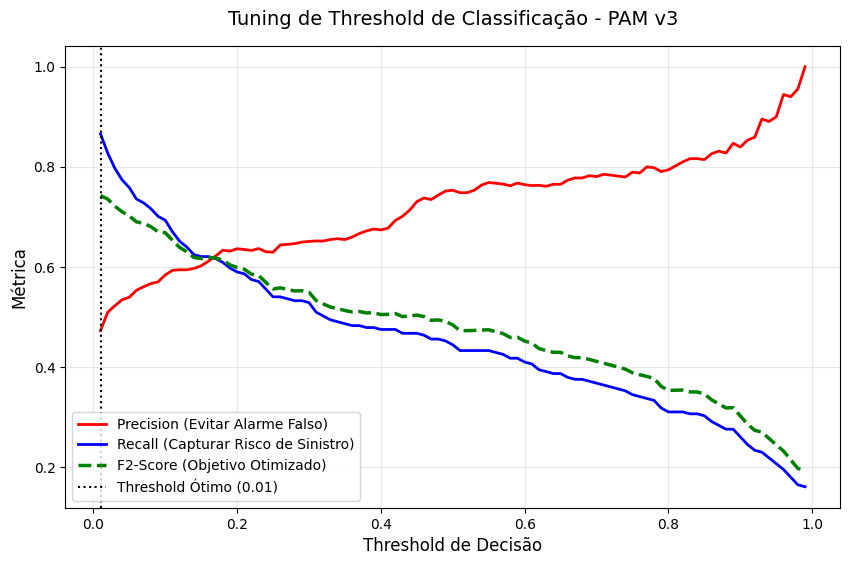

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import fbeta_score, precision_score, recall_score, confusion_matrix

y_proba = model.predict_proba(X_test)[:, 1]

thresholds = np.linspace(0.01, 0.99, 99)
metrics_list = []

for t in thresholds:

    y_pred_t = np.where(y_proba >= t, 1, 0)
    
    f2 = fbeta_score(y_test, y_pred_t, beta=2, zero_division=0)
    precision = precision_score(y_test, y_pred_t, zero_division=0)
    recall = recall_score(y_test, y_pred_t, zero_division=0)
    
    metrics_list.append({
        'threshold': t,
        'F2_Score': f2,
        'Precision': precision,
        'Recall': recall
    })

tuning_df = pd.DataFrame(metrics_list)

best_row = tuning_df.loc[tuning_df['F2_Score'].idxmax()]
best_threshold = best_row['threshold']

print("--- RESULTADOS DO TUNING DE THRESHOLD (Foco: Minimizar Falsos Negativos) ---")
print(f"Melhor Threshold Encontrado: {best_threshold:.2f}")
print(f"F2-Score Máximo: {best_row['F2_Score']:.4f}")
print(f"Precision correspondente: {best_row['Precision']:.4f}")
print(f"Recall correspondente (Aumento crítico!): {best_row['Recall']:.4f}\n")

y_pred_otimo = np.where(y_proba >= best_threshold, 1, 0)
tn, fp, fn, tp = confusion_matrix(y_test, y_pred_otimo).ravel()

print("--- MATRIZ DE CONFUSÃO COM THRESHOLD OTIMIZADO ---")
print(f"Verdadeiros Negativos (Aderentes corretos): {tn}")
print(f"Falsos Positivos (Alarmes Falsos para a Operadora): {fp}")
print(f"Falsos Negativos (Risco de Sinistro Oculto - CAIU!): {fn}")
print(f"Verdadeiros Positivos (Não-Aderentes Capturados - SUBIU!): {tp}\n")

plt.figure(figsize=(10, 6))
sns.lineplot(data=tuning_df, x='threshold', y='Precision', label='Precision (Evitar Alarme Falso)', color='red', linewidth=2)
sns.lineplot(data=tuning_df, x='threshold', y='Recall', label='Recall (Capturar Risco de Sinistro)', color='blue', linewidth=2)
sns.lineplot(data=tuning_df, x='threshold', y='F2_Score', label='F2-Score (Objetivo Otimizado)', color='green', linestyle='--', linewidth=2.5)

plt.axvline(x=best_threshold, color='black', linestyle=':', label=f'Threshold Ótimo ({best_threshold:.2f})')
plt.title('Tuning de Threshold de Classificação - PAM v3', fontsize=14, pad=15)
plt.xlabel('Threshold de Decisão', fontsize=12)
plt.ylabel('Métrica', fontsize=12)
plt.legend(loc='lower left')
plt.grid(True, alpha=0.3)
plt.show()

In [4]:
col_names = 'threshold F2_Score Precision Recall'.split()

pd.DataFrame({col_name:[metric_dict[col_name] for metric_dict in metrics_list] for col_name in col_names}).to_csv('./results/class_thresholds_metrics.csv')

Optimizing Threshold based on estimated ROI optimization

In [6]:
import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix

# --- Premissas hipotéticas (ilustrativas) ---
CUSTO_INTERNACAO = 15000.0
EFICACIA_INTERVENCAO = 0.30
INTERNACOES_POR_NAO_ADESAO_POR_MIL = 5.0   
PREVALENCIA_NAO_ADERENTE = 0.36            

p_hosp_dado_nao_aderente = (INTERNACOES_POR_NAO_ADESAO_POR_MIL / 1000) / PREVALENCIA_NAO_ADERENTE

# "Valor" de um verdadeiro positivo
valor_tp = CUSTO_INTERNACAO * EFICACIA_INTERVENCAO * p_hosp_dado_nao_aderente

print(f"Valor estimado por TP: R$ {valor_tp:.2f} / paciente-ano")

# --- Cenários de custo por alerta (FP) ---
custos_fp = [0, 5, 10, 15, 30]

thresholds = np.linspace(0.01, 0.99, 99)
resultados = []

for custo_fp in custos_fp:
    for t in thresholds:
        y_pred_t = np.where(y_proba >= t, 1, 0)
        tn, fp, fn, tp = confusion_matrix(y_test, y_pred_t).ravel()
        ev = tp * valor_tp - fp * custo_fp
        resultados.append({
            'custo_fp': custo_fp,
            'threshold': t,
            'TP': tp, 'FP': fp, 'FN': fn, 'TN': tn,
            'expected_value': ev
        })

roi_df = pd.DataFrame(resultados)

otimos = roi_df.loc[roi_df.groupby('custo_fp')['expected_value'].idxmax()]
print(otimos[['custo_fp', 'threshold', 'TP', 'FP', 'expected_value']])

roi_df.to_csv('./results/roi_threshold_scenarios.csv', index=False)
otimos.to_csv('./results/roi_threshold_optimal.csv', index=False)

Valor estimado por TP: R$ 62.50 / paciente-ano
     custo_fp  threshold   TP   FP  expected_value
0           0       0.01  226  252         14125.0
99          5       0.01  226  252         12865.0
198        10       0.01  226  252         11605.0
298        15       0.02  216  208         10380.0
405        30       0.10  181  129          7442.5
